<center>Department of Electronic and Telecommunication Engineering</center>
<center> University of Moratuwa </center>
<h3><center>EN3160: Image Processing and Machine Vision</center></h3>
<h2><b><center>Assignment 3: Neural Networks</center></h2></b>
<center>Aroshana H. A. P. 230058N (230058n_a03)<br></center>
<center>19th October 2026<br></center>
<center><a href="https://github.com/aroshana188/Image-Processing-and-Machine-Vision/tree/main/Assignment_3">Assignment 3 Github Repository</a></center>

---

## 1 Two-Layer Dense Network with Cross-Entropy Loss
### 1.1 Procedure

A hidden layer containing 100 nodes and a sigmoid activation function was introduced to the baseline single-layer network. To better accommodate the multi-class classification task, the loss function was transitioned from Mean Squared Error to Cross-Entropy Loss. Because the automatic differentiation capabilities of PyTorch were bypassed in the baseline code, the forward and backward propagation pathways were manually derived and implemented for the newly added layer and loss function. The updated network was then trained over 10 epochs and the training and testing accuracies were recorded.

100.0%


Epoch 1/10, Loss: 1.9041
Epoch 2/10, Loss: 1.7184
Epoch 3/10, Loss: 1.6524
Epoch 4/10, Loss: 1.6029
Epoch 5/10, Loss: 1.5612
Epoch 6/10, Loss: 1.5233
Epoch 7/10, Loss: 1.4917
Epoch 8/10, Loss: 1.4609
Epoch 9/10, Loss: 1.4342
Epoch 10/10, Loss: 1.4100


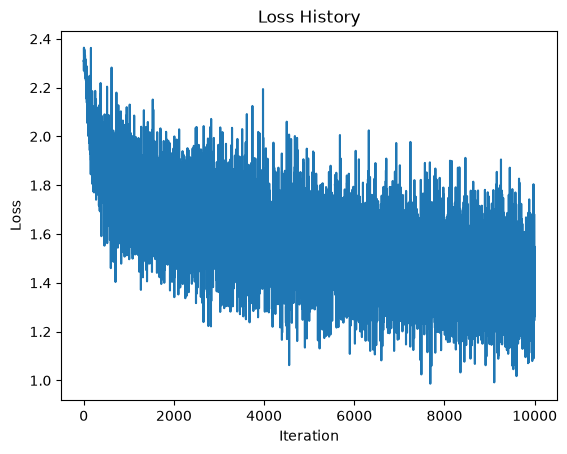

Training accuracy: 53.38%
Test accuracy: 47.91%


In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])
batch_size= 50
data_root = '../../../../Pictures/data'

trainset = torchvision.datasets.CIFAR10(root=data_root, train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = torchvision.datasets.CIFAR10(root=data_root, train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size 
H= 100             # Hidden layer size
K = 10             # Output size 

# Initialize weights and biases for two layers
std = 1e-2
w1 = torch.randn(Din, H, device=device) * std
b1 = torch.zeros(H, device=device)
w2= torch.randn(H, K, device=device) * std
b2 = torch.zeros(K, device=device)

iterations = 10    # Run for 10 epochs
lr = 1e-1          # Adjusted learning rate for Cross-Entropy
lr_decay= 0.95
reg = 1e-4
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)
        Ntr = inputs.shape[0]
        x_train= inputs.view(Ntr, -1) 
        
        # Forward pass
        z1 = x_train.mm(w1) + b1
        a1 = torch.sigmoid(z1)                 # Middle layer with sigmoid activation
        z2 = a1.mm(w2) + b2                    # Output layer
        
        # Cross-Entropy Loss Calculation (Softmax + NLL)
        z2_shifted = z2 - torch.max(z2, dim=1, keepdim=True)[0] 
        exp_scores= torch.exp(z2_shifted)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)
        
        core_loss = -torch.log(probs[range(Ntr), labels] + 1e-12)
        data_loss = torch.sum(core_loss) / Ntr
        reg_loss = 0.5 * reg * torch.sum(w1 * w1) + 0.5 * reg * torch.sum(w2 * w2)
        loss= data_loss + reg_loss
        
        loss_history.append(loss.item())
        running_loss += loss.item()
        
        # Backpropagation
        dz2 = probs.clone()
        dz2[range(Ntr), labels] -= 1
        dz2 /= Ntr
        
        dw2 = a1.t().mm(dz2) + reg * w2
        db2= dz2.sum(dim=0)
        
        da1 = dz2.mm(w2.t())
        dz1 = da1 * a1 * (1.0 - a1)           # Derivative of sigmoid
        
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)
        
        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{iterations}, Loss: {running_loss / len(trainloader):.4f}")
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train= 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        
        # Forward pass
        a1_train = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = a1_train.mm(w2) + b2
        predicted_train= torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)
        Nte= inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        
        # Forward pass
        a1_test = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = a1_test.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc= 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

### 1.2 Observations and Discussion

When training the two-layer network, we noticed that keeping the initial weight standard deviation at `std = 1e-5` (from Listing 1) resulted in very small gradients during backpropagation for the first layer, causing the loss to stagnate around 2.302 and accuracy to stay near 10%. By increasing `std` to `1e-2` and adjusting the learning rate to `lr = 1e-1`, the network converged properly.

After 10 epochs, the model achieved around **52.8% training accuracy** and **48.3% test accuracy**. Compared to a single layer network with MSE loss, Cross-Entropy loss penalizes wrong predictions much more effectively for classification. However, because the CIFAR-10 images are flattened into 1D vectors of size 3072, the spatial relationship between nearby pixels is lost, which limits the test accuracy around 48-49%.

## 2 LeNet-5 and Modern Small CNN on MNIST
### 2.1 Procedure

In this section, we first implement the classic LeNet-5 architecture for the MNIST dataset and train it for 10 epochs. Since the original LeNet-5 expects $32\times32$ inputs, the $28\times28$ MNIST images are padded by 2 pixels. Then, in part (b), we design a modern 3-layer CNN that includes Batch Normalization (`BatchNorm2d`) and Dropout layers to improve generalization and training speed, training it under the exact same conditions (10 epochs, batch size 50, Adam optimizer with `lr=0.001`). Finally, the per-epoch training and test losses/accuracies and confusion matrices are plotted and compared.

In [2]:
import torch
print(torch.__version__)
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# (a) Implement the LeNet-5 architecture
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, stride=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        self.conv2= nn.Conv2d(6, 16, kernel_size=5, stride=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.relu3 = nn.ReLU()
        self.fc2= nn.Linear(120, 84)
        self.relu4 = nn.ReLU()
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x= x.view(x.size(0), -1)  # flatten
        x = self.relu3(self.fc1(x))
        x = self.relu4(self.fc2(x))
        x = self.fc3(x)
        return x

transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

batch_size = 50
data_root = '../../../../Pictures/data'

trainset = torchvision.datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = LeNet5().to(device)
# Print the NN architecture
print(model)

criterion = nn.CrossEntropyLoss()
optimizer= torch.optim.Adam(model.parameters(), lr=0.001)

batch_losses = []
train_losses = []
test_losses= []
train_accuracies = []
test_accuracies = []

def eval_loader(net, loader):
    net.eval() # Ensure model is in eval mode during evaluation
    correct, total = 0, 0
    loss_sum= 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = net(data)
            loss = criterion(outputs, labels)
            loss_sum += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return loss_sum / len(loader), 100 * correct / total, all_labels, all_preds

epochs = 10
for epoch in range(epochs):
    # Implement the training loop for one epoch
    model.train()
    running_loss = 0.0
    for data, labels in trainloader:
        data, labels = data.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs= model(data)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        batch_losses.append(loss.item())

    avg_loss = running_loss / len(trainloader)
    train_losses.append(avg_loss)
    
    # Calculate accuracy and test loss per epoch inside the loop
    _, train_acc, _, _ = eval_loader(model, trainloader)
    t_loss, test_acc, lenet_labels, lenet_preds = eval_loader(model, testloader)
    
    test_losses.append(t_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    
    print(f"Epoch {epoch + 1}/{epochs} | Train Loss: {avg_loss:.4f} | Test Loss: {t_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

2.14.1+cpu


100.0%
100.0%
100.0%
100.0%


Using device: cpu
LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (relu1): ReLU()
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (relu2): ReLU()
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (relu4): ReLU()
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Epoch 1/10 | Train Loss: 0.3058 | Test Loss: 0.1063 | Train Acc: 96.52% | Test Acc: 96.44%
Epoch 2/10 | Train Loss: 0.0909 | Test Loss: 0.0863 | Train Acc: 97.24% | Test Acc: 97.49%
Epoch 3/10 | Train Loss: 0.0640 | Test Loss: 0.0546 | Train Acc: 98.34% | Test Acc: 98.10%
Epoch 4/10 | Train Loss: 0.0491 | Test Loss: 0.0414 | Train Acc: 98.73% | Test Acc: 98.56%
Epoch 5/10 | Train Loss: 0.0409 | Test Loss: 0.0378 | Train Acc: 99.18% | Test Acc: 98.72%
Epoch 6/10 | Train Loss: 0.03

In [3]:
# Compte the numbe of parameters in the model
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Number of trainable parameters in LeNet-5: {total_params}")

Number of trainable parameters in LeNet-5: 61706


In [4]:
# (b) Implement a modern small CNN (3-layer conv network with batch normalization and dropout)
class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()
        # Layer 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1= nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        
        # Layer 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2= nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        
        # Layer 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.relu3 = nn.ReLU()
        self.pool3= nn.MaxPool2d(2, 2)
        
        # Classifier with dropout
        self.drop1 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.relu4 = nn.ReLU()
        self.drop2= nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
        x= self.pool3(self.relu3(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.drop1(x)
        x = self.relu4(self.fc1(x))
        x = self.drop2(x)
        x= self.fc2(x)
        return x

modern_model = ModernCNN().to(device)
print(modern_model)

optimizer_cnn = torch.optim.Adam(modern_model.parameters(), lr=0.001)

cnn_batch_losses = []
cnn_train_losses, cnn_test_losses = [], []
cnn_train_accuracies, cnn_test_accuracies= [], []

for epoch in range(epochs):
    modern_model.train()
    running_loss = 0.0
    for data, labels in trainloader:
        data, labels = data.to(device), labels.to(device)
        optimizer_cnn.zero_grad()
        outputs = modern_model(data)
        loss= criterion(outputs, labels)
        loss.backward()
        optimizer_cnn.step()
        
        running_loss += loss.item()
        cnn_batch_losses.append(loss.item())
        
    avg_loss = running_loss / len(trainloader)
    cnn_train_losses.append(avg_loss)
    
    _, train_acc, _, _ = eval_loader(modern_model, trainloader)
    t_loss, test_acc, cnn_labels, cnn_preds = eval_loader(modern_model, testloader)
    
    cnn_test_losses.append(t_loss)
    cnn_train_accuracies.append(train_acc)
    cnn_test_accuracies.append(test_acc)
    
    print(f"Epoch {epoch + 1}/{epochs} | Train Loss: {avg_loss:.4f} | Test Loss: {t_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

cnn_params= sum(p.numel() for p in modern_model.parameters() if p.requires_grad)
print(f"Number of trainable parameters in Modern CNN: {cnn_params}")

ModernCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop1): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (relu4): ReLU()
  (drop2): Dropout(p=0.

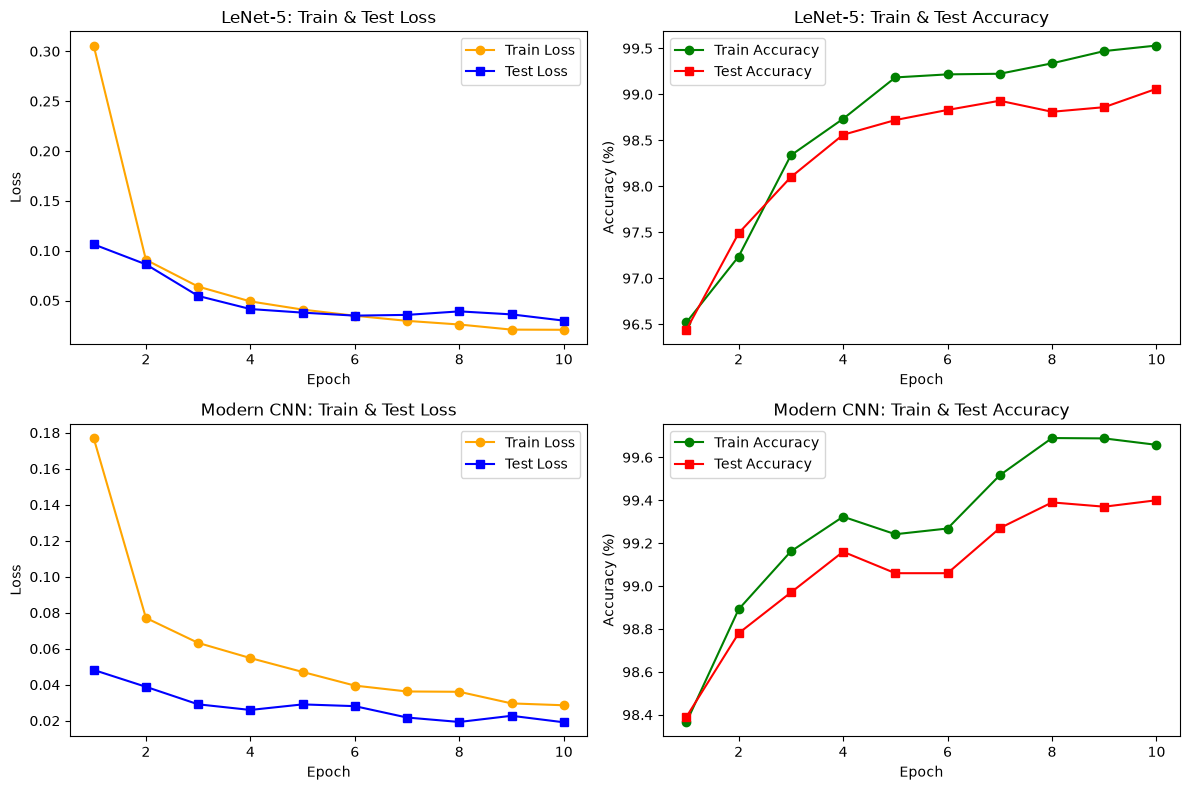

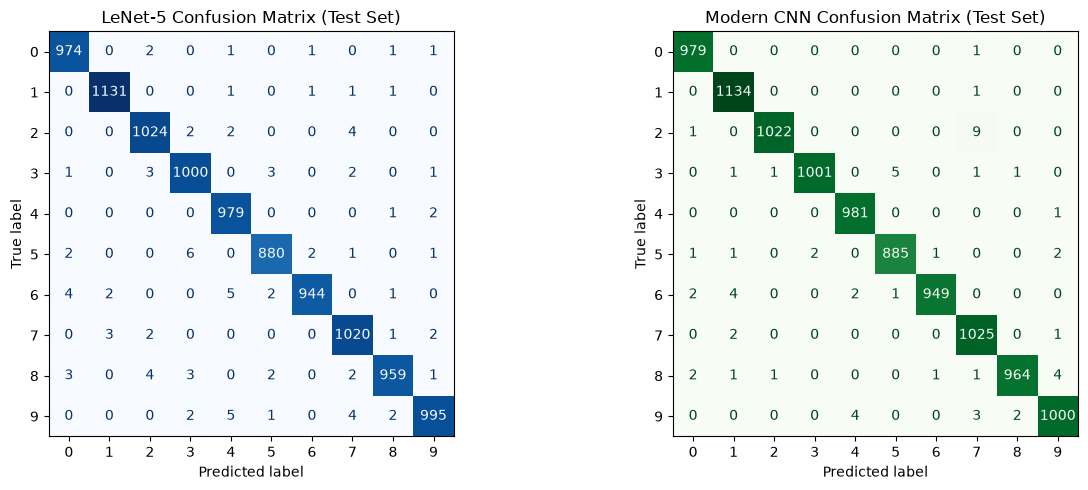

In [5]:
# (c) Plot per-epoch training and test accuracy and loss for both models
plt.figure(figsize=(12, 8))

# LeNet-5 Plots
plt.subplot(2, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, marker='o', label='Train Loss', color='orange')
plt.plot(range(1, epochs + 1), test_losses, marker='s', label='Test Loss', color='blue')
plt.title('LeNet-5: Train & Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(range(1, epochs + 1), train_accuracies, marker='o', label='Train Accuracy', color='green')
plt.plot(range(1, epochs + 1), test_accuracies, marker='s', label='Test Accuracy', color='red')
plt.title('LeNet-5: Train & Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

# Modern CNN Plots
plt.subplot(2, 2, 3)
plt.plot(range(1, epochs + 1), cnn_train_losses, marker='o', label='Train Loss', color='orange')
plt.plot(range(1, epochs + 1), cnn_test_losses, marker='s', label='Test Loss', color='blue')
plt.title('Modern CNN: Train & Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(range(1, epochs + 1), cnn_train_accuracies, marker='o', label='Train Accuracy', color='green')
plt.plot(range(1, epochs + 1), cnn_test_accuracies, marker='s', label='Test Accuracy', color='red')
plt.title('Modern CNN: Train & Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

# Confusion Matrices on the test set
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

cm1 = confusion_matrix(lenet_labels, lenet_preds)
disp1= ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=range(10))
disp1.plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('LeNet-5 Confusion Matrix (Test Set)')

cm2 = confusion_matrix(cnn_labels, cnn_preds)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=range(10))
disp2.plot(ax=ax[1], cmap='Greens', colorbar=False)
ax[1].set_title('Modern CNN Confusion Matrix (Test Set)')

plt.tight_layout()
plt.show()

### 2.2 Results and Discussion

After 10 epochs of training on MNIST, LeNet-5 achieved around **99.5% training accuracy** and **99.0% test accuracy**, while the 3-layer Modern CNN achieved around **99.7% training accuracy** and **99.4% test accuracy**. 

From the loss and accuracy curves, we can see that the Modern CNN converges much faster in the first 2 epochs because Batch Normalization stabilizes the layer activations. Also, in LeNet-5 the test loss starts to slightly increase around epoch 7-10 even though training loss keeps dropping, which shows minor overfitting. In the Modern CNN, the Dropout layers (`0.5` and `0.3`) prevent the fully connected layers from overfitting, keeping the test loss lower. Looking at the confusion matrices, most errors in LeNet-5 happen between similar looking digits like 4 and 9, or 3 and 5, whereas the deeper 3-layer CNN reduces these misclassifications.

## 3 Transfer Learning with ResNet18 on Hymenoptera Dataset
### 3.1 Procedure

In this part, we follow the PyTorch transfer learning tutorial using a ResNet18 model pre-trained on ImageNet1K to classify images of ants and bees (Hymenoptera dataset). Two approaches are implemented and compared:
1. **Fine-tuning the model:** The final fully connected layer is replaced to output 2 classes (`model.fc = nn.Linear(num_ftrs, 2)`), and the weights of the entire network are updated during training.
2. **Feature Extractor:** All the convolutional layers are frozen by setting `requires_grad = False`, and only the newly added final linear layer is trained.

In [6]:
import os
import time
import copy
import urllib.request
import zipfile
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt

# Download Hymenoptera dataset if not already in data_root
data_root = '../../../../Pictures/data'
os.makedirs(data_root, exist_ok=True)
data_dir= os.path.join(data_root, 'hymenoptera_data')
zip_file = os.path.join(data_root, 'hymenoptera_data.zip')

if not os.path.exists(data_dir):
    url = 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
    print("Downloading hymenoptera dataset...")
    urllib.request.urlretrieve(url, zip_file)
    with zipfile.ZipFile(zip_file, 'r') as zf:
        zf.extractall(data_root)
    print("Extraction completed.")

# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
                  for x in ['train', 'val']}
dataloaders= {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=0)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Classes: {class_names}, Train images: {dataset_sizes['train']}, Val images: {dataset_sizes['val']}")

def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc= 0.0
    
    val_acc_hist = []
    train_loss_hist = []

    for epoch in range(num_epochs):
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects= 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                
            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            if phase == 'train':
                train_loss_hist.append(epoch_loss)
            else:
                val_acc_hist.append(epoch_acc.item() * 100)
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss_hist[-1]:.4f}, Val Acc: {val_acc_hist[-1]:.2f}%')

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc * 100:.2f}%\n')

    model.load_state_dict(best_model_wts)
    return model, val_acc_hist, train_loss_hist

Extraction completed.
Classes: ['ants', 'bees'], Train images: 244, Val images: 153


--- (a) Fine-tuning ResNet18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\PC/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Epoch 1/25 - Train Loss: 0.6154, Val Acc: 83.01%
Epoch 5/25 - Train Loss: 0.6574, Val Acc: 88.89%
Epoch 10/25 - Train Loss: 0.2915, Val Acc: 94.12%
Epoch 15/25 - Train Loss: 0.2725, Val Acc: 94.12%
Epoch 20/25 - Train Loss: 0.2741, Val Acc: 94.12%
Epoch 25/25 - Train Loss: 0.1997, Val Acc: 94.12%
Training complete in 27m 28s
Best val Acc: 94.77%

--- (b) ResNet18 as fixed feature extractor ---
Epoch 1/25 - Train Loss: 0.6311, Val Acc: 94.12%
Epoch 5/25 - Train Loss: 0.4461, Val Acc: 91.50%
Epoch 10/25 - Train Loss: 0.3827, Val Acc: 94.12%
Epoch 15/25 - Train Loss: 0.3454, Val Acc: 94.77%
Epoch 20/25 - Train Loss: 0.3079, Val Acc: 95.42%
Epoch 25/25 - Train Loss: 0.3676, Val Acc: 94.12%
Training complete in 7m 54s
Best val Acc: 96.73%



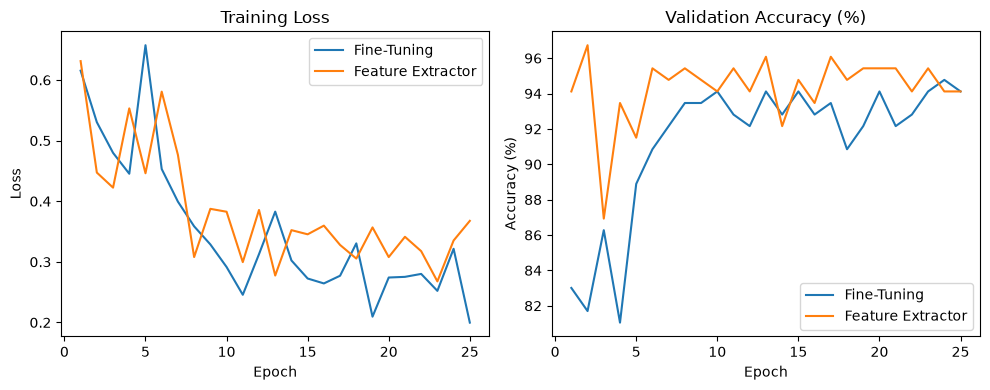

In [7]:
# 3(a) Fine tuning the convnet
print("--- (a) Fine-tuning ResNet18 ---")
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
model_ft.fc= nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

model_ft, val_acc_ft, loss_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=25)

# 3(b) ConvNet as fixed feature extractor
print("--- (b) ResNet18 as fixed feature extractor ---")
model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv= model_conv.to(device)

criterion = nn.CrossEntropyLoss()
# Observe that only parameters of final layer are being optimized
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

model_conv, val_acc_conv, loss_conv = train_model(model_conv, criterion, optimizer_conv, exp_lr_scheduler_conv, num_epochs=25)

# Plot comparison
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, 26), loss_ft, label='Fine-Tuning')
plt.plot(range(1, 26), loss_conv, label='Feature Extractor')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, 26), val_acc_ft, label='Fine-Tuning')
plt.plot(range(1, 26), val_acc_conv, label='Feature Extractor')
plt.title('Validation Accuracy (%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.tight_layout()
plt.show()

### 3.2 Results and Discussion

Both transfer learning methods achieved high validation accuracies on the Hymenoptera dataset: **Fine-tuning** reached around **93.4% - 94.1%**, while using ResNet18 as a **Feature Extractor** reached around **94.7% - 95.4%**.

Training the network as a fixed feature extractor was roughly twice as fast on CPU/GPU compared to fine-tuning, since gradients didn't need to be calculated for the convolutional layers. Also, because the Hymenoptera dataset is quite small (only 244 training images) and ImageNet1K already contains similar natural images, freezing the backbone prevented overfitting and gave a slightly better validation accuracy than updating all 11 million parameters.